In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [3]:
results_csv = project_root / "results" / "streaming_benchmark_results.csv"
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

if not results_csv.exists():
    raise FileNotFoundError(
        f"The file does not exist at: {results_csv}\n"
        f"Please run the experiments first using:\n"
        "python run_experiments.py"
    )

df = pd.read_csv(results_csv)

In [4]:
summary = df.groupby("method").agg({
    "marginal_coverage": "mean",
    "min_class_coverage": "mean",
    "avg_set_size": "mean",
    "singleton_rate": "mean"
}).reset_index()

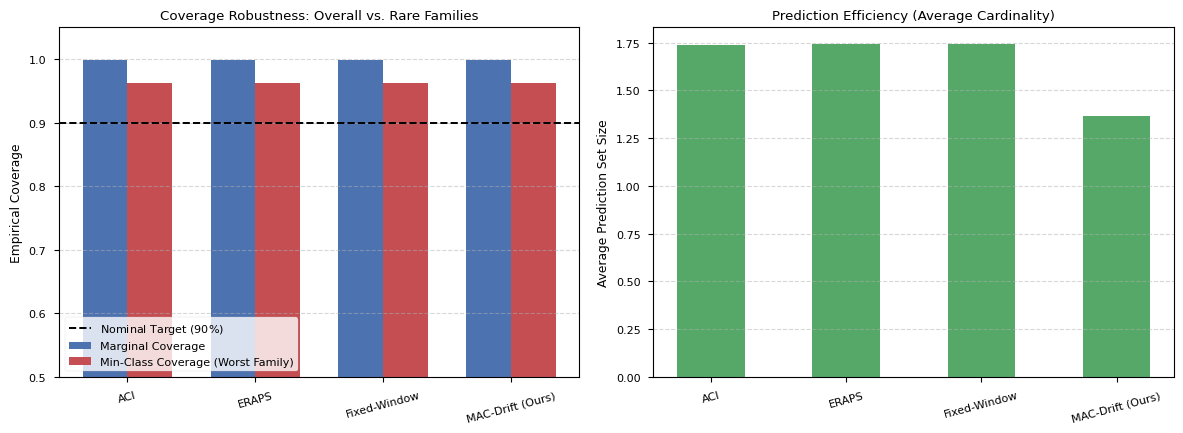

[✓] Figure saved successfully to: D:\Development\projects for master\Paper researcher\MAC Drift Mondrian Adaptive Conformal Inference for Drifting Malware Streams\results\figures\fig3_main_benchmark_tradeoff.pdf


In [ ]:
plt.style.use('seaborn-v0_8-paper')
plt.rcParams.update({'font.size': 12, 'figure.autolayout': True})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

x = np.arange(len(summary))
width = 0.35

ax1.bar(x - width/2, summary["marginal_coverage"], width, label="Marginal Coverage", color="#4c72b0")
ax1.bar(x + width/2, summary["min_class_coverage"], width, label="Min-Class Coverage (Worst Family)", color="#c44e52")
ax1.axhline(0.90, color='black', linestyle='--', label=r"Nominal Target ($90\%$)")
ax1.set_xticks(x)
ax1.set_xticklabels(summary["method"], rotation=15)
ax1.set_ylabel("Empirical Coverage")
ax1.set_ylim(0.5, 1.05)
ax1.set_title("Coverage Robustness: Overall vs. Rare Families")
ax1.legend(loc="lower left")
ax1.grid(True, axis='y', linestyle='--', alpha=0.5)

ax2.bar(summary["method"], summary["avg_set_size"], color="#55a868", width=0.5)
ax2.set_ylabel("Average Prediction Set Size")
ax2.set_title("Prediction Efficiency (Average Cardinality)")
ax2.set_xticks(range(len(summary)))
ax2.set_xticklabels(summary["method"], rotation=15)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
output_fig3 = figures_dir / "fig3_main_benchmark_tradeoff.pdf"
plt.savefig(output_fig3, dpi=300)
plt.show()

print(f"[✓] Figure saved successfully to: {output_fig3}")